**Sameer Almadani**  
**2230001818**

# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
%pip -q install pandas torch matplotlib tensorflow

import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

_ = torch.manual_seed(42)


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: /Users/almadani/Desktop/study/nlp/nlp lab/.venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## Step 2 — Upload the dataset

In [2]:
from pathlib import Path

dataset_path = Path("dataset/Lab_11_QnA_Dataset.csv")
if not dataset_path.exists():
    dataset_path = Path("lab11/dataset/Lab_11_QnA_Dataset.csv")

df = pd.read_csv(dataset_path)
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        states, _ = self.rnn(self.emb(x))
        scores = self.att(states).squeeze(-1)
        scores = scores.masked_fill(x == 0, -1e9)
        weights = torch.softmax(scores, dim=1)
        context = (states * weights.unsqueeze(-1)).sum(1)
        return self.fc(context), weights

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad()
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")
print(f"Final loss: {loss.item():.4f}")

Training finished!
Final loss: 0.0688


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

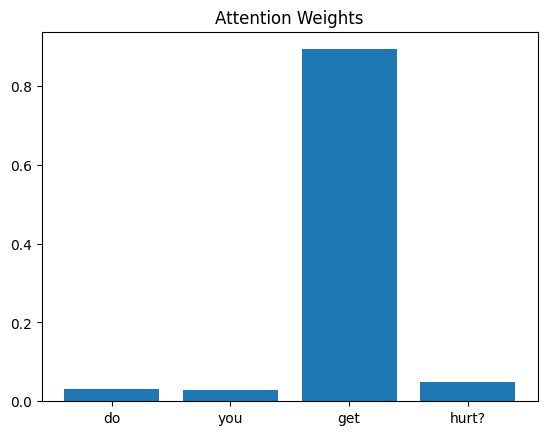

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question: do you get hurt?
Highest attention word: get

Question: are you old?
Highest attention word: old?

Question: who programmed you?
Highest attention word: who



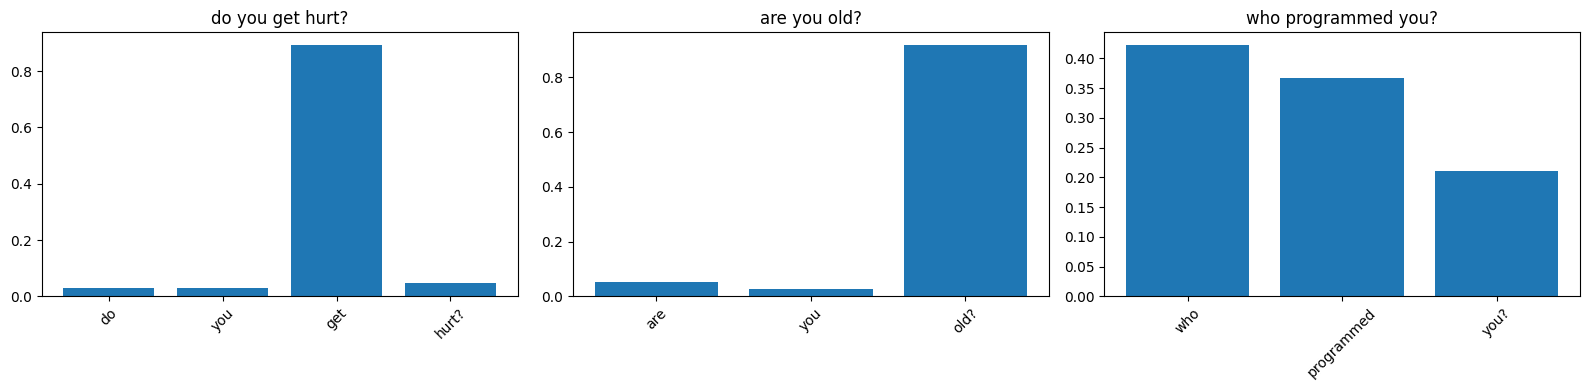

Observation: The highest-weight words help distinguish the topic of each question, although the model learns these weights from a small dataset and may also focus on common question words.


In [7]:
question_indices = [0, 14, 42]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

with torch.no_grad():
    _, selected_weights = model(X[question_indices])

for axis, row_index, attention in zip(axes, question_indices, selected_weights):
    question = df.loc[row_index, "question"]
    words = question.split()
    values = attention[:len(words)].tolist()
    highest_word = words[values.index(max(values))]

    axis.bar(words, values)
    axis.set_title(question)
    axis.tick_params(axis="x", rotation=45)
    print(f"Question: {question}")
    print(f"Highest attention word: {highest_word}")
    print()

plt.tight_layout()
plt.show()
print("Observation: The highest-weight words help distinguish the topic of each question, although the model learns these weights from a small dataset and may also focus on common question words.")

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question: who programmed you?
Highest attention word: who

Question: who created you?
Highest attention word: created



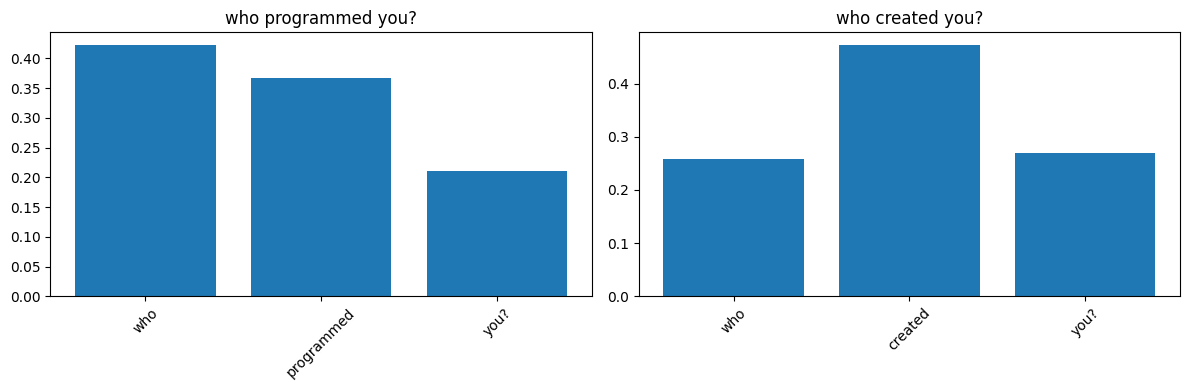

Comparison: The model focused most on 'who' and 'created'. The exact words can differ even when the meaning is similar, showing that attention distributes importance according to each sentence's wording and learned context.


In [8]:
similar_indices = [42, 48]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

with torch.no_grad():
    _, similar_weights = model(X[similar_indices])

highest_words = []
for axis, row_index, attention in zip(axes, similar_indices, similar_weights):
    question = df.loc[row_index, "question"]
    words = question.split()
    values = attention[:len(words)].tolist()
    highest_word = words[values.index(max(values))]
    highest_words.append(highest_word)

    axis.bar(words, values)
    axis.set_title(question)
    axis.tick_params(axis="x", rotation=45)
    print(f"Question: {question}")
    print(f"Highest attention word: {highest_word}")
    print()

plt.tight_layout()
plt.show()
print(f"Comparison: The model focused most on '{highest_words[0]}' and '{highest_words[1]}'. The exact words can differ even when the meaning is similar, showing that attention distributes importance according to each sentence's wording and learned context.")